# Understanding Hierarchical Actor-Critic (HAC): A Complete Guide

### Important Note:

It contains some `bugs` and is not fully functional. The code is provided for educational purposes and may require modifications to work correctly. The focus is on the conceptual understanding of HAC and its implementation in a custom multi-goal grid world environment.

# Table of Contents

- [Introduction: Hierarchy in Reinforcement Learning](#introduction)
- [What is HAC?](#what-is-hac)
  - [Core Idea: Levels of Abstraction & Goal Setting](#core-idea)
  - [Key Mechanisms: Time Limits, Intrinsic Rewards, Hindsight](#key-mechanisms)
- [Why Hierarchical RL? Advantages](#why-hrl)
- [Where and How HAC is Used](#where-and-how-hac-is-used)
- [Mathematical Foundation of HAC (Conceptual)](#mathematical-foundation-of-hac)
  - [Multi-Level Policies & Value Functions](#multi-level-policies--value-functions)
  - [Goal-Conditioned Learning](#goal-conditioned-learning)
  - [Intrinsic Motivation (Subgoal Achievement)](#intrinsic-motivation)
  - [Hindsight Goal Transitions](#hindsight-goal-transitions)
  - [Underlying Off-Policy Algorithm (e.g., DDPG/TD3/SAC adapted)](#underlying-off-policy-algorithm)
- [Step-by-Step Explanation of HAC (2-Level Example)](#step-by-step-explanation-of-hac)
- [Key Components of HAC](#key-components-of-hac)
  - [Hierarchical Layers/Levels](#hierarchical-layerslevels)
  - [Goal Representation](#goal-representation)
  - [Goal-Conditioned Networks (Actor/Critic or Q-Network)](#goal-conditioned-networks)
  - [Time Limit per Level ($H$)](#time-limit-per-level-h)
  - [Subgoal Testing](#subgoal-testing)
  - [Intrinsic Reward Mechanism](#intrinsic-reward-mechanism)
  - [Hindsight Goal/Transition Strategy](#hindsight-goaltransition-strategy)
  - [Replay Buffers (Per Level)](#replay-buffers-per-level)
  - [Hyperparameters](#hyperparameters)
- [Practical Example: Custom Multi-Goal Grid World](#practical-example-custom-multi-goal-grid-world)
  - [Environment Design Rationale for HAC](#environment-design-rationale-for-hac)
- [Setting up the Environment](#setting-up-the-environment)
- [Creating the Custom Grid Environment](#creating-the-custom-grid-environment)
- [Implementing the HAC Algorithm](#implementing-the-hac-algorithm)
  - [Goal/State Representation](#goalstate-representation)
  - [Defining the Low-Level Agent Network (Goal-Conditioned DQN-like)](#defining-the-low-level-agent-network)
  - [Defining the High-Level Agent Network (Goal-Selecting DQN-like)](#defining-the-high-level-agent-network)
  - [Defining the Hindsight Replay Buffer](#defining-the-hindsight-replay-buffer)
  - [Soft Update Function](#soft-update-function)
  - [The HAC Controller/Agent Structure](#the-hac-controlleragent-structure)
    - [Low-Level Action Selection & Training](#low-level-action-selection--training)
    - [High-Level Goal Selection & Training](#high-level-goal-selection--training)
    - [Hindsight Transition Generation](#hindsight-transition-generation)
- [Running the HAC Algorithm](#running-the-hac-algorithm)
  - [Hyperparameter Setup](#hyperparameter-setup)
  - [Initialization](#initialization)
  - [Training Loop](#training-loop)
- [Visualizing the Learning Process](#visualizing-the-learning-process)
- [Analyzing the Learned Policies (Testing)](#analyzing-the-learned-policies-testing)
- [Common Challenges and Extensions of HAC](#common-challenges-and-extensions-of-hac)
- [Conclusion](#conclusion)

## Introduction: Hierarchy in Reinforcement Learning

Many real-world tasks exhibit a natural hierarchical structure. Solving complex problems often involves breaking them down into simpler sub-tasks or achieving intermediate goals. Hierarchical Reinforcement Learning (HRL) aims to leverage this structure by learning policies at multiple levels of temporal abstraction. Higher levels learn to set goals or sequences of sub-tasks, while lower levels learn to execute primitive actions to achieve those goals.

## What is HAC?

Hierarchical Actor-Critic (HAC), introduced by Levy et al. (2019), is a specific HRL algorithm that uses goal-conditioned policies operating at different time scales. It is designed to handle complex tasks with sparse rewards by allowing higher levels to set achievable subgoals for lower levels.

### Core Idea: Levels of Abstraction & Goal Setting
Imagine a multi-layered control system:
- **High Level:** Observes the overall state and chooses a *subgoal* (e.g., a desired state configuration) to achieve within a relatively long time horizon.
- **Low Level:** Receives the current state and the subgoal from the higher level. It then selects *primitive actions* to try and reach that subgoal within a shorter time limit.

Each level acts like an RL agent, learning its own policy (actor) and value function (critic, or Q-function). The 'actions' for higher levels are the subgoals they set for the level below.

### Key Mechanisms: Time Limits, Intrinsic Rewards, Hindsight
HAC incorporates several key ideas:
1.  **Fixed Time Limits ($H$):** Each level (except the lowest) gives the level below it a fixed number of primitive timesteps ($H$) to achieve the assigned subgoal.
2.  **Goal-Conditioned Learning:** Policies and value functions at each level are conditioned not only on the state but also on the goal they are trying to achieve. $Q(state, action, goal)$ or $\pi(action | state, goal)$.
3.  **Intrinsic Motivation:** The lower level receives an intrinsic reward (e.g., +1 or 0) if it successfully reaches the subgoal assigned by the higher level within the time limit, and a penalty (e.g., -1) otherwise. This reward guides the lower level's learning.
4.  **Hindsight Goal Transitions (HER-like):** To combat the sparsity of intrinsic rewards (reaching the *exact* subgoal might be rare initially), HAC uses hindsight. Even if the lower level failed to reach the *intended* goal, it reached *some* final state. HAC stores transitions in the replay buffer as if this *achieved* final state was the *intended* goal. This creates artificial success examples, dramatically improving sample efficiency for goal-conditioned learning.
5.  **Off-Policy Learning:** Because of the hindsight relabeling, the underlying RL algorithm used at each level must be off-policy (like DDPG, TD3, SAC, or adapted DQN/DDQN) to learn from these modified transitions.

## Why Hierarchical RL? Advantages

- **Long Horizon Tasks:** HRL decomposes long, complex tasks into manageable sub-problems, making learning feasible where standard RL might fail due to sparse rewards or credit assignment issues.
- **Structured Exploration:** Higher levels can guide exploration more effectively by setting diverse subgoals, rather than relying solely on random exploration in the primitive action space.
- **Transfer and Reusability:** Lower-level policies trained to achieve specific subgoals might be reusable across different high-level tasks.
- **Improved Sample Efficiency:** Hindsight mechanisms can significantly speed up learning in goal-conditioned tasks.

## Where and How HAC is Used

HAC and similar HRL approaches are applied to:
1.  **Robotics:** Complex manipulation tasks (e.g., stacking blocks, opening doors), locomotion over obstacles.
2.  **Navigation:** Long-range navigation in complex environments (e.g., mazes with keys and doors).
3.  **Game Playing:** Strategy games requiring long-term planning.

## Mathematical Foundation of HAC (Conceptual)

Let's consider a 2-level hierarchy (Level 0: primitive actions, Level 1: sets subgoals for Level 0).

### Multi-Level Policies & Value Functions
- **Level 0 (Low):** Learns policy $\pi_0(a_t | s_t, g_0)$ and value function $Q_0(s_t, a_t, g_0)$. It receives state $s_t$ and a subgoal $g_0$ (set by Level 1) and outputs primitive action $a_t$.
- **Level 1 (High):** Learns policy $\pi_1(g_0 | s_t, G)$ and value function $Q_1(s_t, g_0, G)$. It receives state $s_t$ and the overall task goal $G$ and outputs a subgoal $g_0$ for Level 0.

### Goal-Conditioned Learning
The inputs to the networks explicitly include the goal the level is trying to achieve. This is often done by concatenating the state representation with the goal representation.

### Intrinsic Motivation (Subgoal Achievement)
Level 0 is trained to maximize an intrinsic reward signal based on achieving $g_0$. A simple binary reward:
$$ R_{intrinsic}(s_{t+H}, g_0) = \begin{cases} 0 & \text{if } \text{test_goal}(s_{t+H}, g_0) \text{ is True} \\ -1 & \text{otherwise} \end{cases} $$
where `test_goal` checks if the state reached after $H$ steps satisfies the subgoal $g_0$ (e.g., distance below a threshold).

### Hindsight Goal Transitions
When storing a transition sequence $(s_t, ..., s_{t+H})$ taken by Level 0 aiming for goal $g_0$:
1.  Store the original transition with the original goal $g_0$ and the calculated intrinsic reward $R_{intrinsic}(s_{t+H}, g_0)$.
2.  Store an *additional* hindsight transition: Use the *achieved* state $s_{t+H}$ as the hindsight goal $g'_{0} = s_{t+H}$. The intrinsic reward for this transition is always the success reward (e.g., 0), as the achieved state *is* the goal by definition.
This allows Level 0 to learn how to reach states it happened to land in, even if they weren't the original target.

### Underlying Off-Policy Algorithm (e.g., DDPG/TD3/SAC adapted)
Each level uses an off-policy algorithm to learn its goal-conditioned policy and/or value function from transitions (original and hindsight) stored in its replay buffer. For discrete actions (like our Grid World low level), an adapted DQN/DDQN can be used. For continuous actions/goals (original HAC), DDPG/TD3 is common.

The update involves sampling a batch of goal-conditioned transitions $(s, a, r, s', g)$ and performing the corresponding off-policy update (e.g., Bellman error minimization for Q-learning/critic, policy gradient for actor).

## Step-by-Step Explanation of HAC (2-Level Example)

1.  **Initialize**: Networks $Q_0, Q'_0, Q_1, Q'_1$ (or Actor/Critics), replay buffers $D_0, D_1$. Hyperparameters $H$ (time limit), learning rates, etc.
2.  **Loop for each episode**:
    a.  Call Level 1 to select a subgoal $g_0$ for the overall goal $G$ based on initial state $s_0$. `subgoal = Level1.select_goal(s_0, G)`.
    b.  **Loop (Low-Level Execution)** for $h = 1$ to $H$:
        i.   Call Level 0 to select primitive action $a_t$ based on current state $s_t$ and subgoal $g_0$. `action = Level0.select_action(s_t, g_0)`.
        ii.  Execute $a_t$, observe $r_t, s_{t+1}$.
        iii. Store $(s_t, a_t, r_t, s_{t+1})$ temporarily for the current subgoal attempt.
        iv.  If $s_{t+1}$ achieves subgoal $g_0$ (`test_goal(s_{t+1}, g_0)`), break low-level loop.
        v.   If episode terminates based on environment `done` flag, handle episode end.
        vi.  $s_t \leftarrow s_{t+1}$.
    c.  **End of Subgoal Attempt**: Let the sequence be $s_{start}, a_{start}, ..., s_{end}$.
    d.  **Store Transitions with Hindsight**: 
        - For Level 0 buffer $D_0$: Store original transitions $(s_k, a_k, r_{intrinsic}, s_{k+1}, g_0)$ where $r_{intrinsic}$ depends on whether $s_{end}$ achieved $g_0$. Also store hindsight transitions $(s_k, a_k, 0, s_{k+1}, s_{end})$ (using $s_{end}$ as the achieved goal).
        - For Level 1 buffer $D_1$: Store the high-level transition $(s_{start}, g_0, R_{high}, s_{end}, G)$ where $R_{high}$ is the sum of environment rewards during the subgoal attempt.
    e.  **Perform Updates**: Sample batches from $D_0, D_1$ and update $Q_0, Q_1$ (and target networks) using the underlying off-policy algorithm.
    f.  If the overall goal $G$ is achieved, or max episode steps reached, end episode.
3.  **Repeat**.

## Key Components of HAC

### Hierarchical Layers/Levels
- Multiple policies operating at different temporal abstractions.

### Goal Representation
- How subgoals are defined (e.g., target state, change in state).

### Goal-Conditioned Networks
- Actors/Critics/Q-Networks take state *and* goal as input.

### Time Limit per Level ($H$)
- Maximum steps allocated for a lower level to achieve a subgoal.

### Subgoal Testing
- Function to determine if a state satisfies a given subgoal.

### Intrinsic Reward Mechanism
- How lower levels are rewarded for achieving assigned subgoals.

### Hindsight Goal/Transition Strategy
- Relabeling transitions with achieved goals to improve learning efficiency.

### Replay Buffers (Per Level)
- Store goal-conditioned transitions, including original and hindsight goals.

### Hyperparameters
- Number of levels, time limits $H$ per level.
- Underlying RL algorithm hyperparameters (learning rates, $\tau$, $\gamma$, buffer/batch sizes).
- Subgoal testing tolerance.
- Hindsight strategy parameters.

## Practical Example: Custom Multi-Goal Grid World

### Environment Design Rationale for HAC
Using the Grid World allows us to clearly define:
- **Goals:** Target `(row, col)` tuples.
- **Goal Testing:** Exact match `state == goal`.
- **State/Goal Concatenation:** Easily combine state `(r, c)` and goal `(gr, gc)` as input `(r, c, gr, gc)` to networks.
- **Underlying Algorithm:** Adapt DQN/DDQN for the discrete actions at the lower level and for goal selection at the higher level.

**Environment:** Standard 10x10 grid world. Final goal $G=(9,9)$.
- **Level 1 (High):** Observes state `(r, c)`, selects subgoal $g_0=(gr_0, gc_0)$ from possible grid cells. Aims to reach final goal $G$. Receives environment reward.
- **Level 0 (Low):** Observes state `(r, c)`, receives subgoal $g_0=(gr_0, gc_0)$. Selects primitive actions (U,D,L,R) to reach $g_0$ within $H$ steps. Receives intrinsic reward (-1 or 0).

**Note:** This is a simplified HAC structure. The original paper used DDPG as the base and continuous states/actions.

# Setting up the Environment

Import libraries.

In [1]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from collections import namedtuple, deque, defaultdict
from itertools import count
from typing import List, Tuple, Dict, Optional, Callable, Any, Union
import copy

# Import PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Set up device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set random seeds
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

%matplotlib inline

Using device: cuda


# Creating the Custom Grid Environment

Using the tabular version, suitable for discrete states/goals.

In [2]:
class GridEnvironmentTabular:
    """
    Grid World returning state tuples, suitable for tabular methods.
    Rewards: +10 (goal), -1 (wall), -0.1 (step).
    """
    def __init__(self, rows: int = 10, cols: int = 10) -> None:
        self.rows: int = rows
        self.cols: int = cols
        self.start_state: Tuple[int, int] = (0, 0)
        self.goal_state: Tuple[int, int] = (rows - 1, cols - 1)
        self.state: Tuple[int, int] = self.start_state
        self.action_dim: int = 4
        self.action_map: Dict[int, Tuple[int, int]] = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}

    def reset(self) -> Tuple[int, int]:
        """ Resets environment, returns state tuple. """
        self.state = self.start_state
        return self.state

    def step(self, action: int) -> Tuple[Tuple[int, int], float, bool]:
        """
        Performs one step, returns (next_state_tuple, reward, done).
        """
        if self.state == self.goal_state:
            return self.state, 0.0, True
        
        dr, dc = self.action_map[action]
        current_row, current_col = self.state
        next_row, next_col = current_row + dr, current_col + dc
        
        reward: float = -0.1
        if not (0 <= next_row < self.rows and 0 <= next_col < self.cols):
            next_row, next_col = current_row, current_col # Stay in place
            reward = -1.0
            
        self.state = (next_row, next_col)
        next_state_tuple = self.state
        
        done: bool = (self.state == self.goal_state)
        if done:
            reward = 10.0
            
        return next_state_tuple, reward, done

    def get_action_space_size(self) -> int:
        return self.action_dim
    
    def get_state(self) -> Tuple[int, int]:
        """ Returns the current state. """
        return self.state
    
    # Add this method to GridEnvironmentTabular class
    def is_terminal(self, state: Tuple[int, int]) -> bool:
        """ Checks if the state is terminal (goal state). """
        return state == self.goal_state
        

In [3]:
class GridEnvironmentHAC(GridEnvironmentTabular):
    """ Grid world adapted slightly for HAC state/goal use. """
    def __init__(self, rows: int = 10, cols: int = 10):
        super().__init__(rows=rows, cols=cols)
        # State representation for networks will be normalized
        self.state_dim = 2 # (r, c)
        self.goal_dim = 2 # (gr, gc)
        self.max_coord_float = float(max(rows - 1, cols - 1, 1)) # For normalization

    def _normalize_state_goal(self, state_or_goal: Tuple[int, int]) -> np.ndarray:
        """ Normalizes a state or goal tuple to range [0, 1]. """
        return np.array(state_or_goal, dtype=np.float32) / self.max_coord_float

    def get_normalized_state(self) -> np.ndarray:
        """ Returns the current state, normalized. """
        return self._normalize_state_goal(self.get_state())
    
    # Inherits reset(), step(), is_terminal(), get_possible_actions(), etc.
    # MCTS is not needed, HAC uses learned policies/Q-functions

Instantiate the environment.

In [4]:
hac_env = GridEnvironmentHAC(rows=10, cols=10)
state_dim_hac = hac_env.state_dim
goal_dim_hac = hac_env.goal_dim 
action_dim_hac = hac_env.get_action_space_size()
final_goal_state = hac_env.goal_state # The overall task goal
final_goal_norm = hac_env._normalize_state_goal(final_goal_state)

print(f"HAC Grid Environment: {hac_env.rows}x{hac_env.cols}")
print(f"State Dim: {state_dim_hac}, Goal Dim: {goal_dim_hac}, Action Dim: {action_dim_hac}")
print(f"Final Goal (raw): {final_goal_state}, Final Goal (norm): {final_goal_norm}")

HAC Grid Environment: 10x10
State Dim: 2, Goal Dim: 2, Action Dim: 4
Final Goal (raw): (9, 9), Final Goal (norm): [1. 1.]


# Implementing the HAC Algorithm

We need goal-conditioned networks, a hindsight replay buffer, and the hierarchical control logic.

### Goal/State Representation
Networks will take concatenated `(state, goal)` as input. We'll use normalized coordinates.

### Defining the Low-Level Agent Network (Goal-Conditioned DQN-like)

Takes `(state, goal)` and outputs Q-values for primitive actions.

In [5]:
class GoalConditionedQNetwork(nn.Module):
    """ Outputs Q(state, action | goal). Used for both levels. """
    def __init__(self, input_dim: int, action_dim: int):
        # input_dim = state_dim + goal_dim 
        super(GoalConditionedQNetwork, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_dim) # Q-value per action

    def forward(self, state_goal_concat: torch.Tensor) -> torch.Tensor:
        """ Maps concatenated (state, goal) to Q-values. """
        x = F.relu(self.fc1(state_goal_concat))
        x = F.relu(self.fc2(x))
        q_values = self.fc3(x)
        return q_values

### Defining the High-Level Agent Network (Goal-Selecting DQN-like)

For simplicity, we treat the high level's "action" (selecting a subgoal) as choosing from a discrete set of possible subgoals (e.g., all possible grid cells). This allows using a similar Q-network structure. A more complex approach for continuous goals would use DDPG-like actor/critic. 

*Note: This discretization of the high-level action space is a simplification.*

In [6]:
# The high level selects a goal (state tuple) as its action.
# We need a mapping from action index to goal state tuple.
all_possible_goals = [(r, c) for r in range(hac_env.rows) for c in range(hac_env.cols)]
num_possible_goals = len(all_possible_goals)
action_to_goal_map = {i: goal for i, goal in enumerate(all_possible_goals)}
goal_to_action_map = {goal: i for i, goal in enumerate(all_possible_goals)}

print(f"High level has {num_possible_goals} possible actions (goals).")

# High level uses the same Q-network structure, but output size is num_possible_goals
# Input dim = state_dim + final_goal_dim (which is also state_dim)
high_level_input_dim = state_dim_hac + goal_dim_hac
high_level_action_dim = num_possible_goals

HighLevelQNetwork = GoalConditionedQNetwork # Reuse the class structure

High level has 100 possible actions (goals).


### Defining the Hindsight Replay Buffer

Stores goal-conditioned transitions and relabels their goals in hindsight. Each low-level transition keeps the states its attempt reached afterwards. When it is sampled, with probability $k/(k+1)$ its goal is swapped for one of them (the "future" strategy of Hindsight Experience Replay), and its reward and done flag are recomputed for that goal. An attempt that missed its own subgoal still shows how to reach every state it passed through, so the low level gets useful experience from the first episode on.

In [7]:
# Define transition structure for HAC buffer (the fields each stored transition has)
HACTransition = namedtuple('HACTransition',
                           ('state', 'action', 'reward', 'next_state',
                            'goal', 'done', 'level')) # Add goal and level

class HindsightReplayBuffer:
    """
    Replay buffer for goal-conditioned transitions, with hindsight goal relabeling.

    A transition can carry `future_goals`, the states reached later in the same attempt. When it
    is sampled, with probability `hindsight_prob` its goal is replaced by one of them and the
    reward (0 when the goal is reached, -1 otherwise) and done flag are recomputed for that goal.
    """
    def __init__(self, capacity: int, hindsight_prob: float = 0.8):
        self.memory = deque([], maxlen=capacity)
        self.hindsight_prob = hindsight_prob # Probability of using a hindsight goal

    def push(self, state: np.ndarray, action: int, reward: float,
             next_state: np.ndarray, goal: np.ndarray, done: bool, level: int,
             future_goals: Optional[List[np.ndarray]] = None, env_done: bool = False) -> None:
        """ Saves a transition. `env_done` marks the end of the whole episode. """
        self.memory.append({
            'state': state,
            'action': np.array([action]), # Action index: a primitive action or a subgoal cell
            'reward': reward,
            'next_state': next_state,
            'goal': goal,
            'done': done,
            'level': level,
            'future_goals': future_goals or [],
            'env_done': env_done
        })

    def sample(self, batch_size: int) -> Optional[Tuple[torch.Tensor, ...]]:
        """ Samples a batch, applying hindsight relabeling. """
        if len(self.memory) < batch_size:
            return None
        batch = random.sample(self.memory, batch_size)

        states, actions, rewards, next_states, goals, dones = [], [], [], [], [], []
        for transition in batch:
            goal = transition['goal']
            reward = transition['reward']
            done = transition['done']
            if transition['future_goals'] and random.random() < self.hindsight_prob:
                # Replay the step as if the goal had been a state this attempt reached later on
                goal = random.choice(transition['future_goals'])
                reached = bool(np.abs(transition['next_state'] - goal).max() < 1e-6)
                reward = 0.0 if reached else -1.0
                done = reached or transition['env_done']

            states.append(transition['state'])
            actions.append(transition['action'])
            rewards.append(reward)
            next_states.append(transition['next_state'])
            goals.append(goal)
            dones.append(done)

        # Convert to tensors
        states_t = torch.from_numpy(np.array(states)).float().to(device)
        actions_t = torch.from_numpy(np.array(actions)).long().to(device) # (batch, 1) action indices
        rewards_t = torch.tensor(rewards, dtype=torch.float32).unsqueeze(1).to(device)
        next_states_t = torch.from_numpy(np.array(next_states)).float().to(device)
        goals_t = torch.from_numpy(np.array(goals)).float().to(device)
        dones_t = torch.tensor(dones, dtype=torch.float32).unsqueeze(1).to(device)

        return states_t, actions_t, rewards_t, next_states_t, goals_t, dones_t

    def __len__(self) -> int:
        return len(self.memory)

### Soft Update Function

Standard soft update.

In [8]:
def soft_update(target_net: nn.Module, main_net: nn.Module, tau: float) -> None:
    for target_param, main_param in zip(target_net.parameters(), main_net.parameters()):
        target_param.data.copy_(tau * main_param.data + (1.0 - tau) * target_param.data)

### The HAC Controller/Agent Structure

A class `HACAgent` manages the two levels, their interaction, and their updates. Every $H$ primitive steps the high level proposes a subgoal cell, and the low level gets up to $H$ primitive actions to reach it. Two hindsight mechanisms let both levels learn at the same time:

- **Hindsight goals (low level):** the replay buffer above relabels low-level attempts with states they actually reached.
- **Hindsight actions (high level):** the high level is trained as if it had proposed the state the low level actually reached, not the subgoal it asked for. Its experience then does not depend on how good the low level was when it was collected, which keeps the high level's learning problem stationary while the low level improves.

Both levels use Double DQN updates, one per new transition.

*Simplifications against the paper (Levy et al., 2019): two levels, discrete actions and subgoals (Q-learning instead of DDPG), a high level trained on the environment's reward rather than on a goal reward, and no subgoal-testing transitions (which penalize subgoals the low level cannot reach).*

In [9]:
class HACAgent:
    def __init__(self,
                 env: GridEnvironmentHAC,
                 num_levels: int,
                 H: int,  # Time limit per level
                 k_hindsight: int,  # Hindsight goals per real low-level transition
                 buffer_size: int,
                 batch_size: int,
                 gamma: float,
                 tau: float,
                 actor_lr: float,  # Using Q-networks, so this is Q-net LR
                 epsilon_start: float,
                 epsilon_end: float,
                 device: torch.device):

        if num_levels != 2:
            raise NotImplementedError("Only 2 levels implemented")

        self.env = env
        self.num_levels = num_levels
        self.H = H  # Max steps for low level to achieve high-level goal
        self.k = k_hindsight
        self.buffer_size = buffer_size
        self.batch_size = batch_size
        self.gamma = gamma
        self.tau = tau
        self.lr = actor_lr
        self.epsilon_start = epsilon_start
        self.epsilon_end = epsilon_end
        self.device = device

        self.state_dim = env.state_dim
        self.goal_dim = env.goal_dim
        self.primitive_action_dim = env.get_action_space_size()
        self.subgoal_action_dim = env.rows * env.cols  # High level action = choosing a cell
        self.final_goal_raw = env.goal_state
        self.final_goal_norm = env._normalize_state_goal(self.final_goal_raw)
        self.final_goal_tensor = torch.from_numpy(self.final_goal_norm).float().to(device)

        # --- Level 0 (Low Level) Components ---
        self.low_level_qnet = GoalConditionedQNetwork(self.state_dim + self.goal_dim, self.primitive_action_dim).to(
            device)
        self.low_level_target_qnet = GoalConditionedQNetwork(self.state_dim + self.goal_dim,
                                                              self.primitive_action_dim).to(device)
        self.low_level_target_qnet.load_state_dict(self.low_level_qnet.state_dict())
        self.low_level_optimizer = optim.Adam(self.low_level_qnet.parameters(), lr=self.lr)
        # k hindsight goals per real transition means relabeling a sampled transition with
        # probability k / (k + 1), the same ratio as storing k relabeled copies of each
        self.low_level_buffer = HindsightReplayBuffer(buffer_size, hindsight_prob=self.k / (self.k + 1))

        # --- Level 1 (High Level) Components ---
        self.high_level_qnet = GoalConditionedQNetwork(self.state_dim + self.goal_dim, self.subgoal_action_dim).to(
            device)
        self.high_level_target_qnet = GoalConditionedQNetwork(self.state_dim + self.goal_dim,
                                                               self.subgoal_action_dim).to(device)
        self.high_level_target_qnet.load_state_dict(self.high_level_qnet.state_dict())
        self.high_level_optimizer = optim.Adam(self.high_level_qnet.parameters(), lr=self.lr)
        # The high level always pursues the final goal; its hindsight is in the action instead
        self.high_level_buffer = HindsightReplayBuffer(buffer_size // H, hindsight_prob=0.0)  # High level gets less data

        self.total_steps = 0  # Primitive steps in the current episode
        self.current_epsilon = self.epsilon_start
        self.proposed_subgoals: List[Tuple[int, int]] = []  # Subgoals of the latest top-level run

    def _test_goal(self, state: np.ndarray, goal: np.ndarray) -> bool:
        """ Check if state achieves goal (the same grid cell). """
        state_raw = tuple(np.round(state * self.env.max_coord_float).astype(int))
        goal_raw = tuple(np.round(goal * self.env.max_coord_float).astype(int))
        return state_raw == goal_raw

    def _cell(self, state_norm: np.ndarray) -> Tuple[int, int]:
        """ The grid cell (row, col) of a normalized state or goal. """
        r, c = np.round(state_norm * self.env.max_coord_float).astype(int)
        return int(r), int(c)

    def select_action(self, level: int, state_norm: np.ndarray, goal_norm: np.ndarray) -> int:
        """ Select an action index (primitive action or subgoal cell) using epsilon-greedy. """
        if level == 0:
            qnet = self.low_level_qnet
            action_dim = self.primitive_action_dim
        else:  # Level 1
            qnet = self.high_level_qnet
            action_dim = self.subgoal_action_dim

        if random.random() < self.current_epsilon:
            return random.randrange(action_dim)

        state_tensor = torch.from_numpy(state_norm).float().to(self.device)
        goal_tensor = torch.from_numpy(goal_norm).float().to(self.device)
        state_goal_concat = torch.cat([state_tensor, goal_tensor]).unsqueeze(0)  # Add batch dim
        with torch.no_grad():
            q_values = qnet(state_goal_concat).squeeze(0)
        return int(q_values.argmax().item())

    def run_level(self, level: int, initial_state_norm: np.ndarray, goal_norm: np.ndarray) -> Tuple[
        List[Dict], float, bool, np.ndarray]:
        """
        Run one level of the hierarchy for up to H of its steps.
        Returns: list of transitions (of this level and the levels below), cumulative env reward,
        goal achieved flag, final state.
        """
        state_norm = initial_state_norm
        cumulative_env_reward = 0.0
        transitions = []
        goal_achieved = False
        if level == 1:
            self.proposed_subgoals = []

        for t in range(self.H):
            if level == 0:  # Low level executes primitive actions
                action = self.select_action(0, state_norm, goal_norm)
                _, env_reward, env_done = self.env.step(action)
                next_state_norm = self.env.get_normalized_state()
                reached = self._test_goal(next_state_norm, goal_norm)

                # Store low-level transition (goal reward: 0 when the subgoal is reached, -1 otherwise)
                transitions.append({
                    'state': state_norm,
                    'action': action,
                    'reward': 0.0 if reached else -1.0,
                    'next_state': next_state_norm,
                    'goal': goal_norm,
                    'done': reached or env_done,
                    'level': 0,
                    'env_done': env_done
                })

                cumulative_env_reward += env_reward
                state_norm = next_state_norm
                self.total_steps += 1  # Count primitive steps

                if reached:
                    goal_achieved = True
                    break
                if env_done:  # The episode is over (the final goal was reached)
                    break

            else:  # High level proposes a subgoal and lets the low level pursue it
                subgoal_index = self.select_action(1, state_norm, goal_norm)
                subgoal_cell = action_to_goal_map[subgoal_index]
                self.proposed_subgoals.append(subgoal_cell)
                subgoal_norm = self.env._normalize_state_goal(subgoal_cell)
                segment_start_norm = state_norm  # The state this subgoal was chosen in

                low_level_transitions, low_level_env_reward, _, segment_end_norm = \
                    self.run_level(level=0, initial_state_norm=state_norm, goal_norm=subgoal_norm)

                # The low level learns from its own steps, relabeled with the states it reached afterwards
                for j, low_trans in enumerate(low_level_transitions):
                    low_trans['future_goals'] = [later['next_state'] for later in low_level_transitions[j:]]
                transitions.extend(low_level_transitions)

                cumulative_env_reward += low_level_env_reward
                env_done = self.env.is_terminal(self.env.get_state())

                # Store the high-level transition with a hindsight action: the cell the low level
                # actually reached, as if the high level had proposed it
                transitions.append({
                    'state': segment_start_norm,
                    'action': goal_to_action_map[self._cell(segment_end_norm)],
                    'reward': low_level_env_reward,  # Environment reward collected on the way
                    'next_state': segment_end_norm,
                    'goal': goal_norm,  # The final goal
                    'done': env_done,
                    'level': 1
                })

                state_norm = segment_end_norm
                if env_done:  # The final goal was reached
                    goal_achieved = True
                    break

        return transitions, cumulative_env_reward, goal_achieved, state_norm

    def store_and_update(self, transitions: List[Dict]) -> Tuple[float, float]:
        """ Store an episode's transitions, then run one update per new transition at each level. """
        new_transitions = {0: 0, 1: 0}
        for trans in transitions:
            buffer = self.low_level_buffer if trans['level'] == 0 else self.high_level_buffer
            buffer.push(**trans)
            new_transitions[trans['level']] += 1

        avg_losses = []
        for level in (0, 1):
            losses = [self.update_level(level) for _ in range(new_transitions[level])]
            losses = [loss for loss in losses if loss is not None]
            avg_losses.append(float(np.mean(losses)) if losses else 0.0)
        return avg_losses[0], avg_losses[1]

    def update_level(self, level: int) -> Optional[float]:
        """ One Double DQN update of a level's Q-network from a (hindsight) batch. """
        if level == 0:
            qnet = self.low_level_qnet
            target_qnet = self.low_level_target_qnet
            optimizer = self.low_level_optimizer
            buffer = self.low_level_buffer
        else:
            qnet = self.high_level_qnet
            target_qnet = self.high_level_target_qnet
            optimizer = self.high_level_optimizer
            buffer = self.high_level_buffer

        # Sample batch with hindsight relabeling
        sample = buffer.sample(self.batch_size)
        if sample is None:
            return None  # Not enough samples yet

        states_t, actions_t, rewards_t, next_states_t, goals_t, dones_t = sample

        # Concatenate state and goal for network input
        state_goal_input = torch.cat([states_t, goals_t], dim=1)
        next_state_goal_input = torch.cat([next_states_t, goals_t], dim=1)

        # --- Critic (Q-Network) Update ---
        # Q-values of the actions taken (stored as indices at both levels)
        current_q = qnet(state_goal_input).gather(1, actions_t)

        # Get target Q values using target network (Double DQN style)
        with torch.no_grad():
            # Select best action for next state using *main* network
            best_next_action = qnet(next_state_goal_input).argmax(dim=1, keepdim=True)
            # Evaluate this best action using *target* network
            max_next_q = target_qnet(next_state_goal_input).gather(1, best_next_action)
            # Compute TD target
            td_target = rewards_t + self.gamma * (1.0 - dones_t) * max_next_q

        # Calculate loss
        loss = F.mse_loss(current_q, td_target)

        # Optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Soft update target network
        soft_update(target_qnet, qnet, self.tau)

        return loss.item()

# Running the HAC Algorithm

### Hyperparameter Setup

In [10]:
# Hyperparameters for HAC on Custom Grid World
BUFFER_SIZE_HAC = int(1e5)
BATCH_SIZE_HAC = 128
GAMMA_HAC = 0.98 # Discount factor (might be lower for HRL)
TAU_HAC = 1e-3   # Soft update factor
LR_HAC = 1e-4    # Learning rate for Q-networks
EPSILON_HAC_START = 1.0
EPSILON_HAC_END = 0.05 # Reached at the last episode (linear decay per episode)
H_TIMESCALE = 10 # Time limit per level: up to H subgoals, each with up to H primitive steps
K_HINDSIGHT = 4  # Hindsight goals per real low-level transition (relabel probability k/(k+1) = 0.8)

NUM_EPISODES_HAC = 500
MAX_TOTAL_STEPS_EPISODE = H_TIMESCALE * H_TIMESCALE # Max primitive steps per *overall* episode

### Initialization

In [11]:
# Initialize Environment
hac_env_run = GridEnvironmentHAC(rows=10, cols=10)

# Initialize HAC Agent
hac_agent = HACAgent(
    env=hac_env_run,
    num_levels=2,
    H=H_TIMESCALE,
    k_hindsight=K_HINDSIGHT,
    buffer_size=BUFFER_SIZE_HAC,
    batch_size=BATCH_SIZE_HAC,
    gamma=GAMMA_HAC,
    tau=TAU_HAC,
    actor_lr=LR_HAC,
    epsilon_start=EPSILON_HAC_START,
    epsilon_end=EPSILON_HAC_END,
    device=device
)

# Lists for plotting
hac_episode_rewards = [] # Store *environment* rewards
hac_episode_lengths = []
hac_episode_epsilons = []
hac_low_level_losses = []
hac_high_level_losses = []

### Training Loop

In [12]:
# Training Loop
print("Starting HAC Training...")

for i_episode in range(1, NUM_EPISODES_HAC + 1):
    # Reset env and get initial state (normalized)
    hac_agent.env.reset()
    current_state_norm = hac_agent.env.get_normalized_state()
    hac_agent.total_steps = 0  # Primitive steps in this episode

    # Run the top level (Level 1) toward the final goal. It calls the low level for every
    # subgoal, so the returned transitions hold the experience of both levels.
    transitions, episode_env_reward, _, _ = hac_agent.run_level(
        level=1,
        initial_state_norm=current_state_norm,
        goal_norm=hac_agent.final_goal_norm
    )
    episode_steps = hac_agent.total_steps

    # Store the transitions and learn from replay (one update per new transition at each level)
    ep_low_loss, ep_high_loss = hac_agent.store_and_update(transitions)

    # --- Logging ---
    hac_episode_rewards.append(episode_env_reward)
    hac_episode_lengths.append(episode_steps)  # Log total primitive steps
    hac_episode_epsilons.append(hac_agent.current_epsilon)
    hac_low_level_losses.append(ep_low_loss)
    hac_high_level_losses.append(ep_high_loss)

    if i_episode % 20 == 0:
        avg_reward = np.mean(hac_episode_rewards[-20:])
        avg_length = np.mean(hac_episode_lengths[-20:])
        avg_ll_loss = np.mean(hac_low_level_losses[-20:])
        avg_hl_loss = np.mean(hac_high_level_losses[-20:])
        print(
            f"Ep {i_episode}/{NUM_EPISODES_HAC} | Avg Reward: {avg_reward:.2f} | Avg Length: {avg_length:.1f} | L0_Loss: {avg_ll_loss:.4f} | L1_Loss: {avg_hl_loss:.4f} | Eps: {hac_agent.current_epsilon:.3f}")

    # Update epsilon (linear decay over the episodes)
    hac_agent.current_epsilon = max(hac_agent.epsilon_end, hac_agent.epsilon_start - i_episode / NUM_EPISODES_HAC * (
                hac_agent.epsilon_start - hac_agent.epsilon_end))

print("Training Finished (HAC).")

Starting HAC Training...


Ep 20/500 | Avg Reward: -17.00 | Avg Length: 96.8 | L0_Loss: 0.3021 | L1_Loss: 1.6379 | Eps: 0.964


Ep 40/500 | Avg Reward: -18.23 | Avg Length: 95.0 | L0_Loss: 0.4937 | L1_Loss: 2.5400 | Eps: 0.926


Ep 60/500 | Avg Reward: -16.17 | Avg Length: 93.0 | L0_Loss: 0.4244 | L1_Loss: 1.2752 | Eps: 0.888


Ep 80/500 | Avg Reward: -14.76 | Avg Length: 94.7 | L0_Loss: 0.2404 | L1_Loss: 1.1739 | Eps: 0.850


Ep 100/500 | Avg Reward: -13.23 | Avg Length: 85.0 | L0_Loss: 0.1318 | L1_Loss: 1.1985 | Eps: 0.812


... (16 outputs left out)

Ep 440/500 | Avg Reward: 7.19 | Avg Length: 25.1 | L0_Loss: 0.0170 | L1_Loss: 0.6599 | Eps: 0.166


Ep 460/500 | Avg Reward: 7.76 | Avg Length: 22.1 | L0_Loss: 0.0137 | L1_Loss: 0.5796 | Eps: 0.128


Ep 480/500 | Avg Reward: 7.63 | Avg Length: 23.4 | L0_Loss: 0.0150 | L1_Loss: 0.6002 | Eps: 0.090


Ep 500/500 | Avg Reward: 7.83 | Avg Length: 20.4 | L0_Loss: 0.0140 | L1_Loss: 0.6060 | Eps: 0.052
Training Finished (HAC).


# Visualizing the Learning Process

Plot overall episode rewards and lengths, and optionally the losses for each level.

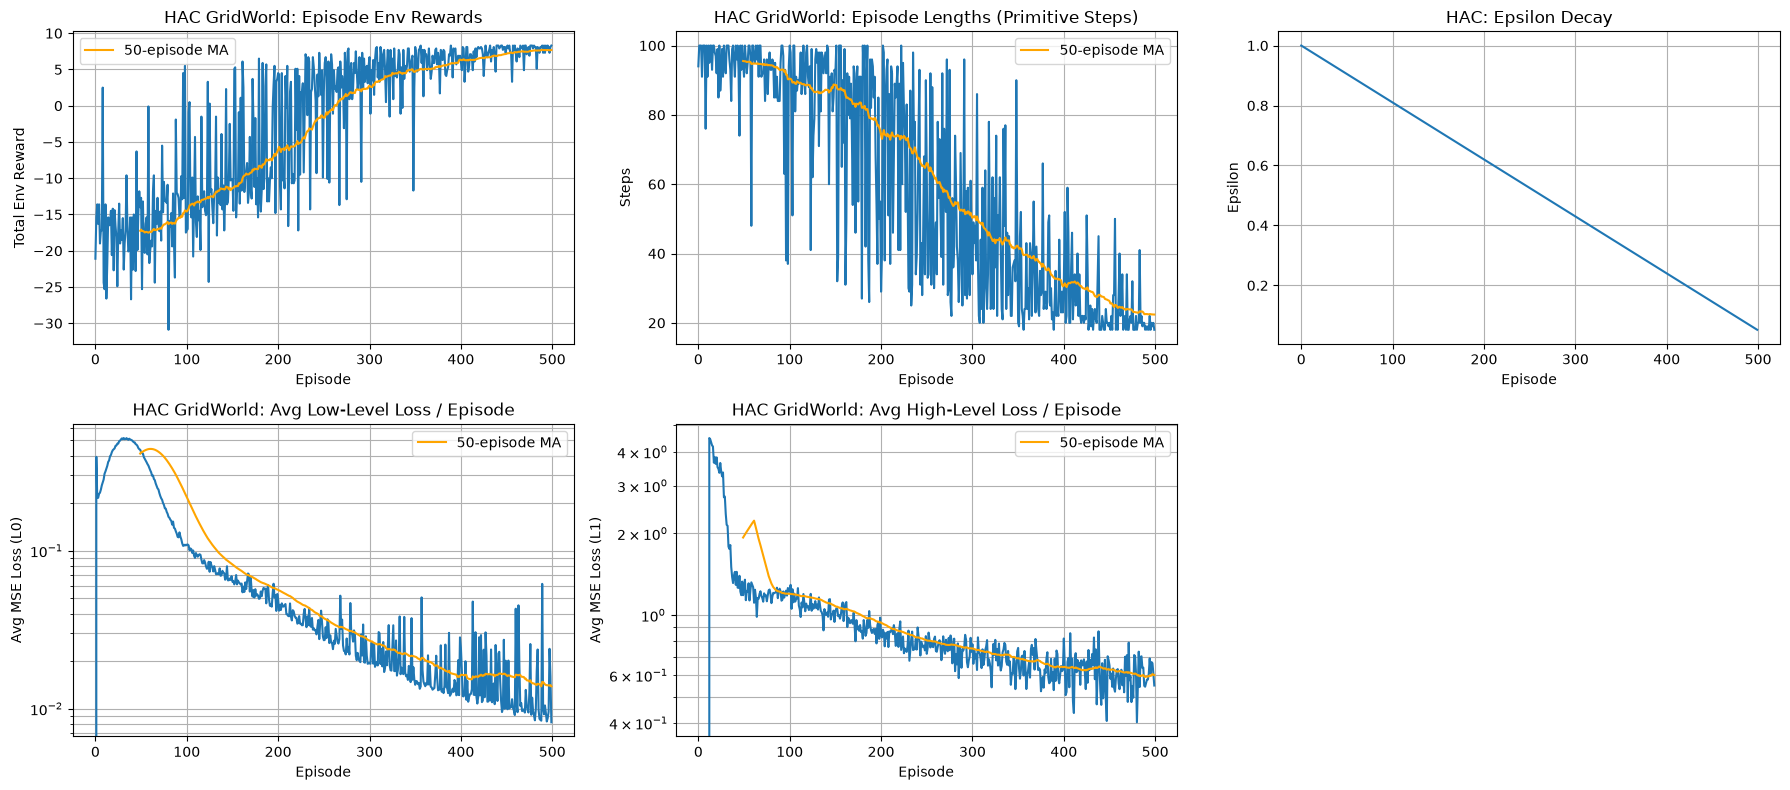

In [13]:
# Plotting results for HAC
plt.figure(figsize=(18, 8))

# Episode Rewards (Environment Reward)
plt.subplot(2, 3, 1)
plt.plot(hac_episode_rewards)
plt.title('HAC GridWorld: Episode Env Rewards')
plt.xlabel('Episode')
plt.ylabel('Total Env Reward')
plt.grid(True)
if len(hac_episode_rewards) >= 50:
    rewards_ma_hac = np.convolve(hac_episode_rewards, np.ones(50)/50, mode='valid')
    plt.plot(np.arange(len(rewards_ma_hac)) + 49, rewards_ma_hac, label='50-episode MA', color='orange')
    plt.legend()

# Episode Lengths (Primitive Steps)
plt.subplot(2, 3, 2)
plt.plot(hac_episode_lengths)
plt.title('HAC GridWorld: Episode Lengths (Primitive Steps)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.grid(True)
if len(hac_episode_lengths) >= 50:
    lengths_ma_hac = np.convolve(hac_episode_lengths, np.ones(50)/50, mode='valid')
    plt.plot(np.arange(len(lengths_ma_hac)) + 49, lengths_ma_hac, label='50-episode MA', color='orange')
    plt.legend()

# Epsilon
plt.subplot(2, 3, 3)
plt.plot(hac_episode_epsilons)
plt.title('HAC: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(True)

# Low Level Loss
plt.subplot(2, 3, 4)
plt.plot(hac_low_level_losses)
plt.title('HAC GridWorld: Avg Low-Level Loss / Episode')
plt.xlabel('Episode')
plt.ylabel('Avg MSE Loss (L0)')
plt.yscale('log')
plt.grid(True, which='both')
if len(hac_low_level_losses) >= 50:
    ll_loss_ma = np.convolve(hac_low_level_losses, np.ones(50)/50, mode='valid')
    valid_indices = np.where(ll_loss_ma > 1e-8)[0]
    if len(valid_indices) > 0:
        plt.plot(np.arange(len(ll_loss_ma))[valid_indices] + 49, ll_loss_ma[valid_indices], label='50-episode MA', color='orange')
        plt.legend()

# High Level Loss
plt.subplot(2, 3, 5)
plt.plot(hac_high_level_losses)
plt.title('HAC GridWorld: Avg High-Level Loss / Episode')
plt.xlabel('Episode')
plt.ylabel('Avg MSE Loss (L1)')
plt.yscale('log')
plt.grid(True, which='both')
if len(hac_high_level_losses) >= 50:
    hl_loss_ma = np.convolve(hac_high_level_losses, np.ones(50)/50, mode='valid')
    valid_indices = np.where(hl_loss_ma > 1e-8)[0]
    if len(valid_indices) > 0:
        plt.plot(np.arange(len(hl_loss_ma))[valid_indices] + 49, hl_loss_ma[valid_indices], label='50-episode MA', color='orange')
        plt.legend()

plt.tight_layout()
plt.show()

**Analysis of HAC Learning Curves:**

1.  **Environment rewards and lengths:** Both levels learn. The average reward climbs from about -17 in the first episodes to 7.8 over the last 20 (the best possible is 8.3, for the 18-step path), and the episode length falls from the 100-step limit (10 subgoals of 10 steps) to about 20. Epsilon decays linearly, so the last episodes still explore a little.
2.  **Losses:** The low level's loss rises while its buffer fills with random experience, peaks around episode 30, and then falls by more than an order of magnitude, to about 0.01: with hindsight goals, every attempt teaches it how to reach the cells it passed through. The high level's loss falls from about 4 to about 0.6; it stays higher because its targets are sums of up to ten environment rewards, including the +10 for the goal. The first episodes log 0 for both because no update runs until a buffer holds a full batch of 128 transitions.
3.  **The test (below):** with greedy policies at both levels, all five test episodes reach the goal in 18 steps, the shortest path, for the maximum reward of 8.30.

**What the hierarchy learned:** the high level proposes the final goal (9, 9) itself, twice: the low level gets 10 steps toward it, then 8 more. On an open 10x10 grid that is the best plan, so intermediate subgoals have nothing to add, and the low level's goal-reaching skill does the work. Subgoals pay off where the direct route is blocked or the goal is too far for one low-level attempt, as in mazes or longer horizons.

# Analyzing the Learned Policies (Testing)

Test the agent by running the hierarchical policy stack.

In [14]:
def test_hac_agent(agent: HACAgent,
                   env_instance: GridEnvironmentHAC,
                   num_episodes: int = 5) -> None:
    """ Tests the trained HAC agent with greedy policies at both levels. """
    print(f"\n--- Testing HAC Agent ({num_episodes} episodes) ---")
    all_episode_rewards = []
    all_episode_lengths = []

    # Greedy policies at both levels
    original_epsilon = agent.current_epsilon
    agent.current_epsilon = 0.0

    for i in range(num_episodes):
        env_instance.reset()
        current_state_norm = env_instance.get_normalized_state()
        agent.total_steps = 0 # Primitive steps in this episode

        # Run the top level (which recursively calls lower levels)
        _, episode_env_reward, reached_goal, _ = agent.run_level(
            level=1,
            initial_state_norm=current_state_norm,
            goal_norm=agent.final_goal_norm
        )
        total_primitive_steps = agent.total_steps

        print(f"Test Episode {i+1}: Reward = {episode_env_reward:.2f}, Length = {total_primitive_steps}, "
              f"Reached goal: {reached_goal}, Subgoals proposed: {agent.proposed_subgoals}")
        all_episode_rewards.append(episode_env_reward)
        all_episode_lengths.append(total_primitive_steps)

    # Restore original epsilon
    agent.current_epsilon = original_epsilon
    print(f"--- Testing Complete. Average Reward: {np.mean(all_episode_rewards):.2f}, Avg Length: {np.mean(all_episode_lengths):.1f} ---")

# Run test episodes
test_hac_agent(hac_agent, hac_env_run, num_episodes=5)


--- Testing HAC Agent (5 episodes) ---
Test Episode 1: Reward = 8.30, Length = 18, Reached goal: True, Subgoals proposed: [(9, 9), (9, 9)]
Test Episode 2: Reward = 8.30, Length = 18, Reached goal: True, Subgoals proposed: [(9, 9), (9, 9)]
Test Episode 3: Reward = 8.30, Length = 18, Reached goal: True, Subgoals proposed: [(9, 9), (9, 9)]
Test Episode 4: Reward = 8.30, Length = 18, Reached goal: True, Subgoals proposed: [(9, 9), (9, 9)]
Test Episode 5: Reward = 8.30, Length = 18, Reached goal: True, Subgoals proposed: [(9, 9), (9, 9)]
--- Testing Complete. Average Reward: 8.30, Avg Length: 18.0 ---


## Common Challenges and Extensions of HAC

**Challenge: Goal Representation**
*   **Problem:** Defining effective subgoals (actions for higher levels) is crucial but non-trivial. Using absolute states (like grid cells) can be limiting.
*   **Solutions**:
    *   **Relative Goals:** Define goals as desired *changes* in state.
    *   **Learned Goal Spaces:** Learn an appropriate embedding space for goals.

**Challenge: Subgoal Feasibility & Non-Stationarity**
*   **Problem:** The high level might set subgoals that the low level cannot currently achieve, wasting time. Also, as the low level learns, the high level's task (selecting good subgoals) changes (non-stationarity).
*   **Solutions**:
    *   **Goal Filtering:** High level only proposes goals deemed achievable by the low level (e.g., based on value estimates).
    *   **Coordinated Training:** Careful scheduling of updates between levels.

**Challenge: Time Limit ($H$) Tuning**
*   **Problem:** Setting the right time limit $H$ is difficult. Too short, and subgoals are rarely achieved; too long, and learning becomes slow and less hierarchical.
   **Solutions**:
    *   **Adaptive $H$:** Try to learn or adapt $H$ based on task complexity or success rates.
    *   **Remove Fixed Limit:** Some HRL methods use termination conditions other than fixed time limits.

**Challenge: Complexity & Hyperparameters**
*   **Problem:** HRL methods like HAC introduce many new design choices and hyperparameters (number of levels, goal space, intrinsic rewards, time limits, hindsight strategy) on top of the base RL algorithm's parameters.
   **Solution:** Careful implementation, systematic tuning, starting with settings from literature.

**Challenge: Hindsight Implementation Details**
*   **Problem:** Correctly implementing the storage and sampling of hindsight goals (final vs. future strategies, how rewards/dones are set for hindsight transitions) is critical and can be subtle.
   **Solution:** Follow standard HER/HAC practices carefully.

**Extensions:**
- **HIRO:** Uses relative goals.
- **RIG:** Learns goal representations.
- **Feudal Networks:** Earlier HRL approach with manager/worker structure.

## Conclusion

Hierarchical Actor-Critic (HAC) provides a framework for tackling complex, long-horizon reinforcement learning tasks by introducing multiple levels of control. Higher levels set goals (subgoals) for lower levels, which in turn execute actions to achieve them. Key mechanisms like goal-conditioning, fixed time limits per level, intrinsic rewards for subgoal achievement, and hindsight goal relabeling enable learning in challenging scenarios, particularly those with sparse rewards.

While significantly more complex to implement and tune than flat RL algorithms, HAC and other HRL methods offer a promising direction for improving exploration, sample efficiency, and the ability to solve problems requiring reasoning over extended time scales. The core idea of decomposing tasks and learning goal-conditioned policies remains a central theme in advanced reinforcement learning research.